## CE2 Phase 11: Subgroup Fairness, Ethics & Final Comparison

In this culminating phase of CE2, we synthesize the empirical findings from our machine learning investigations, rigorously select our final model, evaluate subgroup fairness across demographic attributes, and contextualize our results within ethical and societal frameworks.

### 1. Final Model Selection via the One-Standard-Deviation Rule
Model selection involves balancing goodness-of-fit against model complexity (the principle of parsimony, or Occam's razor). Rather than simply choosing the model with the absolute highest mean cross-validation score—which may marginally outperform simpler alternatives due to random sample variation—we apply the **one-standard-deviation (1-std / 1-SE) rule**:
1. Estimate out-of-sample performance using 5-fold cross-validation on the **training set only**: compute the mean and standard error/deviation for each candidate model.
2. Identify the best model ($M^*$) having the highest cross-validation score $\mu^*$, with cross-validation standard deviation $\sigma^*$.
3. Define the selection threshold as:
   $$\text{Threshold} = \mu^* - \sigma^*$$
4. Choose the **simplest model** whose mean cross-validation score satisfies $\mu \ge \text{Threshold}$.

If a simpler model performs within one standard deviation of the most complex model, its performance is statistically indistinguishable from the top model, while offering superior interpretability, lower computational burden, and reduced risk of overfitting.

### 2. Algorithmic Fairness: Error Parity vs. Demographic Parity
Fairness in machine learning is multifaceted and depends fundamentally on the problem formulation:
- **Demographic Parity (Statistical Parity)**: Requires that the probability of a positive outcome is equal across protected demographic groups:
  $$P(\hat{Y} = 1 \mid A = a) = P(\hat{Y} = 1 \mid A = b)$$
  Demographic parity is designed for discrete decision-making systems (e.g., loan approvals, hiring decisions). It requires defining an explicit decision policy or threshold and ignores ground-truth label distributions.
- **Error Parity (Predictive Parity / Equalized Accuracy)**: In continuous regression problems, fairness is framed through **error parity**: evaluating whether predictive accuracy and error metrics are uniform across protected attributes:
  - **Mean Absolute Error (MAE)**: Measures average prediction magnitude discrepancy across groups.
  - **Mean Signed Error ($\mathbb{E}[\hat{y} - y]$)**: Measures directional bias (systematic overestimation or underestimation) for specific subgroups.

### 3. Understanding Subgroup Disparities
Disparities in subgroup error metrics do not automatically indicate algorithmic prejudice or discriminatory features. In real-world facial datasets like UTKFace, subgroup performance variations arise from multiple interacting factors:
1. **Differential Label Spread**: If one demographic subgroup has a wider ground-truth age distribution or higher standard deviation in age, the baseline difficulty of predicting age for that group is inherently greater.
2. **Sample Size Disparities**: Small demographic subsets (e.g., sample sizes $N < 50$) yield high sampling variance, causing wider confidence intervals and volatile empirical error estimates.
3. **Landmark Detection Variance**: Morphological and textural differences across ancestral and age phenotypes affect computer vision landmark extraction accuracy.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ensure correct working directory
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Load full unscaled datasets (14 feature columns) and target series
X_train = pd.read_csv("data/processed/X_train.csv")
X_test = pd.read_csv("data/processed/X_test.csv")
y_train = pd.read_csv("data/processed/y_train.csv")["age"]
y_test = pd.read_csv("data/processed/y_test.csv")["age"]

# Build human-readable subgroup labels from X_test BEFORE dropping reference dummies
# Note: Labels follow documented UTKFace codes and are kept generic (Race_0 through Race_4)
gender_label = np.where(X_test["gender_1"] == 1, "Female (1)", "Male (0)")
race_label = X_test[["race_0", "race_1", "race_2", "race_3", "race_4"]].idxmax(axis=1).map(lambda c: c.capitalize())

# Feature column definitions
continuous_cols = [
    "eye_distance", "mouth_width", "face_width", "face_height",
    "face_aspect_ratio", "eye_to_face_ratio", "mouth_to_face_ratio"
]
dummy_cols = ["gender_1", "race_1", "race_2", "race_3", "race_4"]

# Drop reference dummies (gender_0, race_0) to prevent perfect multicollinearity
X_train_mlr = X_train.drop(columns=["gender_0", "race_0"])
X_test_mlr = X_test.drop(columns=["gender_0", "race_0"])

# Print dataset summary and subgroup representations in test set
print("=== Dataset Dimensions ===")
print(f"X_train_mlr shape: {X_train_mlr.shape}, y_train shape: {y_train.shape}")
print(f"X_test_mlr shape:  {X_test_mlr.shape}, y_test shape:  {y_test.shape}")
print(f"\nContinuous features ({len(continuous_cols)}): {continuous_cols}")
print(f"Dummy features ({len(dummy_cols)}):      {dummy_cols}")

print("\n=== Test Set Demographic Distribution (N = {}) ===".format(len(y_test)))
print("\nGender Subgroups:")
gender_counts = pd.Series(gender_label).value_counts()
for grp, cnt in gender_counts.items():
    print(f"  {grp:<12}: {cnt:3d} ({cnt / len(y_test) * 100:.1f}%)")

print("\nRace Subgroups:")
race_counts = pd.Series(race_label).value_counts().sort_index()
for grp, cnt in race_counts.items():
    print(f"  {grp:<12}: {cnt:3d} ({cnt / len(y_test) * 100:.1f}%)")


=== Dataset Dimensions ===
X_train_mlr shape: (2398, 12), y_train shape: (2398,)
X_test_mlr shape:  (600, 12), y_test shape:  (600,)

Continuous features (7): ['eye_distance', 'mouth_width', 'face_width', 'face_height', 'face_aspect_ratio', 'eye_to_face_ratio', 'mouth_to_face_ratio']
Dummy features (5):      ['gender_1', 'race_1', 'race_2', 'race_3', 'race_4']

=== Test Set Demographic Distribution (N = 600) ===

Gender Subgroups:
  Male (0)    : 307 (51.2%)
  Female (1)  : 293 (48.8%)

Race Subgroups:
  Race_0      : 269 (44.8%)
  Race_1      : 107 (17.8%)
  Race_2      :  89 (14.8%)
  Race_3      :  98 (16.3%)
  Race_4      :  37 (6.2%)



In [2]:
# Cell 3: Final Model Selection via 5-Fold Cross-Validation on Training Data Only
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Identify best continuous feature by absolute Pearson correlation with y_train (training data only)
corrs = {col: np.corrcoef(X_train[col], y_train)[0, 1] for col in continuous_cols}
best_feature = max(corrs, key=lambda k: abs(corrs[k]))
print(f"Highest correlated continuous feature on training data: '{best_feature}' (r = {corrs[best_feature]:.4f})")

# Construct three candidate pipelines with StandardScaler inside ColumnTransformer
# 1. Simple Linear Regression (best single continuous feature)
pipe_simple = Pipeline([
    ("prep", ColumnTransformer([("s", StandardScaler(), [best_feature])])),
    ("reg", LinearRegression())
])

# 2. Multiple Linear Regression (all continuous + demographic dummies)
pipe_mlr = Pipeline([
    ("prep", ColumnTransformer([
        ("s", StandardScaler(), continuous_cols),
        ("d", "passthrough", dummy_cols)
    ])),
    ("reg", LinearRegression())
])

# 3. Polynomial Regression (degree 2 on continuous + demographic dummies)
pipe_poly = Pipeline([
    ("prep", ColumnTransformer([
        ("p", Pipeline([
            ("s", StandardScaler()),
            ("poly", PolynomialFeatures(degree=2, include_bias=False))
        ]), continuous_cols),
        ("d", "passthrough", dummy_cols)
    ])),
    ("reg", LinearRegression())
])

# Evaluate candidates with 5-fold cross-validation on UNSCALED X_train_mlr
candidate_models = [
    ("Simple LR", pipe_simple),
    ("Multiple LR", pipe_mlr),
    ("Polynomial (degree 2)", pipe_poly)
]

cv_results = {}
print("\n=== 5-Fold Cross-Validation Performance (Training Data Only) ===")
for name, pipe in candidate_models:
    scores = cross_val_score(pipe, X_train_mlr, y_train, cv=cv, scoring="r2")
    cv_results[name] = {"mean": scores.mean(), "std": scores.std()}
    print(f"{name:<22}: Mean R² = {scores.mean():.4f}, Std = {scores.std():.4f}")

# Model selection via the 1-standard-deviation rule
best_model_name = max(cv_results, key=lambda k: cv_results[k]["mean"])
best_mean = cv_results[best_model_name]["mean"]
best_std = cv_results[best_model_name]["std"]
threshold = best_mean - best_std

print(f"\nTop-performing model by CV Mean R²: {best_model_name} (Mean = {best_mean:.4f}, Std = {best_std:.4f})")
print(f"1-Standard-Deviation Selection Threshold: {best_mean:.4f} - {best_std:.4f} = {threshold:.4f}")

# Find simplest model satisfying CV mean >= threshold
# Complexity order: Simple LR < Multiple LR < Polynomial (degree 2)
chosen_model_name = None
for name in ["Simple LR", "Multiple LR", "Polynomial (degree 2)"]:
    if cv_results[name]["mean"] >= threshold:
        chosen_model_name = name
        break

chosen_pipeline = dict(candidate_models)[chosen_model_name]
print(f"\n>>> FINAL SELECTED MODEL: '{chosen_model_name}' <<<")
print(f"Reason: '{chosen_model_name}' is the simplest model whose CV Mean R² ({cv_results[chosen_model_name]['mean']:.4f}) "
      f"exceeds the 1-std threshold ({threshold:.4f}).")

# Compare with historical ce2_cv_results.csv if present
cv_file = "data/processed/ce2_cv_results.csv"
if os.path.exists(cv_file):
    try:
        prev_cv = pd.read_csv(cv_file)
        print("\nHistorical CV reference from ce2_cv_results.csv:")
        print(prev_cv.to_string(index=False))
    except Exception as e:
        print(f"Note: Could not parse {cv_file}: {e}")


Highest correlated continuous feature on training data: 'face_aspect_ratio' (r = 0.2585)

=== 5-Fold Cross-Validation Performance (Training Data Only) ===
Simple LR             : Mean R² = 0.0638, Std = 0.0218
Multiple LR           : Mean R² = 0.1637, Std = 0.0139
Polynomial (degree 2) : Mean R² = 0.1427, Std = 0.0365

Top-performing model by CV Mean R²: Multiple LR (Mean = 0.1637, Std = 0.0139)
1-Standard-Deviation Selection Threshold: 0.1637 - 0.0139 = 0.1498

>>> FINAL SELECTED MODEL: 'Multiple LR' <<<
Reason: 'Multiple LR' is the simplest model whose CV Mean R² (0.1637) exceeds the 1-std threshold (0.1498).

Historical CV reference from ce2_cv_results.csv:
                           Model  CV_R2_Mean  CV_R2_Std  CV_MAE_Mean  CV_MAE_Std  CV_RMSE_Mean  CV_RMSE_Std  Train_R2_Mean
                 Baseline (Mean)   -0.002529   0.003375    15.505870    0.243409     20.060375     0.558887       0.000000
   Simple LR (face_aspect_ratio)    0.063800   0.021832    15.264645    0.338965     

In [3]:
# Cell 4: Final Test Set Evaluation and Bootstrap Confidence Intervals
# Fit the selected model on the entire training set
chosen_pipeline.fit(X_train_mlr, y_train)
y_pred_chosen = chosen_pipeline.predict(X_test_mlr)

# Fit DummyRegressor baseline (predicting mean training age)
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train_mlr, y_train)
y_pred_base = baseline.predict(X_test_mlr)

# Compute point test metrics
test_mae_chosen = mean_absolute_error(y_test, y_pred_chosen)
test_rmse_chosen = np.sqrt(mean_squared_error(y_test, y_pred_chosen))
test_r2_chosen = r2_score(y_test, y_pred_chosen)

test_mae_base = mean_absolute_error(y_test, y_pred_base)
test_rmse_base = np.sqrt(mean_squared_error(y_test, y_pred_base))
test_r2_base = r2_score(y_test, y_pred_base)

print("=== Final Holdout Test Performance (N = 600) ===")
print(f"{'Metric':<18} {'Baseline (Mean)':<18} {chosen_model_name:<18} {'Gain (Improvement)':<18}")
print("-" * 72)
print(f"{'MAE (years)':<18} {test_mae_base:<18.4f} {test_mae_chosen:<18.4f} {test_mae_base - test_mae_chosen:<18.4f}")
print(f"{'RMSE (years)':<18} {test_rmse_base:<18.4f} {test_rmse_chosen:<18.4f} {test_rmse_base - test_rmse_chosen:<18.4f}")
print(f"{'R² Score':<18} {test_r2_base:<18.4f} {test_r2_chosen:<18.4f} {test_r2_chosen - test_r2_base:<18.4f}")

# Bootstrap 95% Confidence Intervals (1000 resamples, seed 42)
rng = np.random.default_rng(42)
n_test = len(y_test)
boot_mae, boot_r2, boot_gain = [], [], []

for _ in range(1000):
    idx = rng.choice(n_test, size=n_test, replace=True)
    y_true_b = y_test.iloc[idx]
    y_pred_b = y_pred_chosen[idx]
    y_base_b = y_pred_base[idx]
    
    mae_b = mean_absolute_error(y_true_b, y_pred_b)
    base_mae_b = mean_absolute_error(y_true_b, y_base_b)
    
    boot_mae.append(mae_b)
    boot_r2.append(r2_score(y_true_b, y_pred_b))
    boot_gain.append(base_mae_b - mae_b)

ci_mae = (np.percentile(boot_mae, 2.5), np.percentile(boot_mae, 97.5))
ci_r2 = (np.percentile(boot_r2, 2.5), np.percentile(boot_r2, 97.5))
ci_gain = (np.percentile(boot_gain, 2.5), np.percentile(boot_gain, 97.5))

print("\n=== Bootstrap 95% Confidence Intervals (1,000 Resamples) ===")
print(f"Test MAE 95% CI:               [{ci_mae[0]:.4f}, {ci_mae[1]:.4f}] years")
print(f"Test R² 95% CI:                [{ci_r2[0]:.4f}, {ci_r2[1]:.4f}]")
print(f"MAE Gain over Baseline 95% CI: [{ci_gain[0]:.4f}, {ci_gain[1]:.4f}] years")
print("Note: The 95% CI for MAE improvement is strictly positive, confirming statistically significant gain over baseline.")


=== Final Holdout Test Performance (N = 600) ===
Metric             Baseline (Mean)    Multiple LR        Gain (Improvement)
------------------------------------------------------------------------
MAE (years)        16.5798            14.7200            1.8598            
RMSE (years)       21.0996            19.1813            1.9183            
R² Score           -0.0021            0.1719             0.1739            

=== Bootstrap 95% Confidence Intervals (1,000 Resamples) ===
Test MAE 95% CI:               [13.7631, 15.6456] years
Test R² 95% CI:                [0.1150, 0.2206]
MAE Gain over Baseline 95% CI: [1.2707, 2.4241] years
Note: The 95% CI for MAE improvement is strictly positive, confirming statistically significant gain over baseline.



In [4]:
# Cell 5: Demographic Subgroup Analysis and Disparity Metrics
def compute_subgroups(attribute_name, labels):
    records = []
    groups = sorted(pd.Series(labels).unique())
    for grp in groups:
        mask = (labels == grp)
        y_true_g = y_test[mask]
        y_pred_g = y_pred_chosen[mask]
        y_base_g = y_pred_base[mask]
        n_g = len(y_true_g)
        
        mean_age = y_true_g.mean()
        base_mae = mean_absolute_error(y_true_g, y_base_g)
        model_mae = mean_absolute_error(y_true_g, y_pred_g)
        mae_gain = base_mae - model_mae
        rmse = np.sqrt(mean_squared_error(y_true_g, y_pred_g))
        mean_signed_err = np.mean(y_pred_g - y_true_g.values)
        
        # Subgroup bootstrap 95% CI for MAE (1,000 resamples within group, seed 42)
        rng_g = np.random.default_rng(42)
        boot_maes = []
        for _ in range(1000):
            idx = rng_g.choice(n_g, size=n_g, replace=True)
            boot_maes.append(mean_absolute_error(y_true_g.iloc[idx], y_pred_g[idx]))
        ci_low = np.percentile(boot_maes, 2.5)
        ci_high = np.percentile(boot_maes, 97.5)
        
        records.append({
            "Attribute": attribute_name,
            "Group": grp,
            "N": n_g,
            "Mean_actual_age": mean_age,
            "Baseline_MAE": base_mae,
            "Model_MAE": model_mae,
            "MAE_gain": mae_gain,
            "RMSE": rmse,
            "Mean_signed_error": mean_signed_err,
            "MAE_CI_low": ci_low,
            "MAE_CI_high": ci_high,
            "Small_group": (n_g < 50)
        })
    return pd.DataFrame(records)

df_gender_sub = compute_subgroups("Gender", gender_label)
df_race_sub = compute_subgroups("Race", race_label)

print("=== Subgroup Performance: Gender ===")
print(df_gender_sub.round(3).to_string(index=False))

print("\n=== Subgroup Performance: Race ===")
print(df_race_sub.round(3).to_string(index=False))

# Disparity summaries per attribute
def summarize_disparity(df_sub, attr_name):
    max_row = df_sub.loc[df_sub["Model_MAE"].idxmax()]
    min_row = df_sub.loc[df_sub["Model_MAE"].idxmin()]
    ratio = max_row["Model_MAE"] / min_row["Model_MAE"]
    diff = max_row["Model_MAE"] - min_row["Model_MAE"]
    # Check if intervals overlap between group with max MAE and min MAE
    overlap = not (min_row["MAE_CI_high"] < max_row["MAE_CI_low"])
    print(f"\n--- Disparity Summary: {attr_name} ---")
    print(f"Largest Model MAE:  {max_row['Model_MAE']:.3f} ({max_row['Group']}, CI: [{max_row['MAE_CI_low']:.3f}, {max_row['MAE_CI_high']:.3f}])")
    print(f"Smallest Model MAE: {min_row['Model_MAE']:.3f} ({min_row['Group']}, CI: [{min_row['MAE_CI_low']:.3f}, {min_row['MAE_CI_high']:.3f}])")
    print(f"Disparity Ratio (Max / Min):      {ratio:.3f}")
    print(f"Disparity Difference (Max - Min): {diff:.3f} years")
    print(f"Bootstrap 95% Confidence Intervals Overlap? {overlap}")
    if overlap:
        print("Interpretation: Group MAE intervals overlap, indicating performance differences are not statistically distinguishable at alpha = 0.05.")
    else:
        print("Interpretation: Group MAE intervals do NOT overlap; disparity is statistically significant, heavily driven by age distribution differences and sample sizes.")

summarize_disparity(df_gender_sub, "Gender")
summarize_disparity(df_race_sub, "Race")

# Combine and save to CSV
df_subgroup_all = pd.concat([df_gender_sub, df_race_sub], ignore_index=True)
subgroup_csv_path = "data/processed/ce2_subgroup_results.csv"
df_subgroup_all.to_csv(subgroup_csv_path, index=False)
print(f"\nSubgroup results saved to '{subgroup_csv_path}'.")


=== Subgroup Performance: Gender ===
Attribute      Group   N  Mean_actual_age  Baseline_MAE  Model_MAE  MAE_gain   RMSE  Mean_signed_error  MAE_CI_low  MAE_CI_high  Small_group
   Gender Female (1) 293           32.116        16.517     14.277     2.239 19.419             -0.599      12.913       15.722        False
   Gender   Male (0) 307           36.150        16.640     15.143     1.497 18.952             -1.594      13.885       16.439        False

=== Subgroup Performance: Race ===
Attribute  Group   N  Mean_actual_age  Baseline_MAE  Model_MAE  MAE_gain   RMSE  Mean_signed_error  MAE_CI_low  MAE_CI_high  Small_group
     Race Race_0 269           40.071        19.991     18.628     1.362 22.648             -2.204      17.056       20.149        False
     Race Race_1 107           31.617        10.684     11.416    -0.732 15.195              1.258       9.587       13.373        False
     Race Race_2  89           26.416        17.664     12.556     5.107 18.690             -

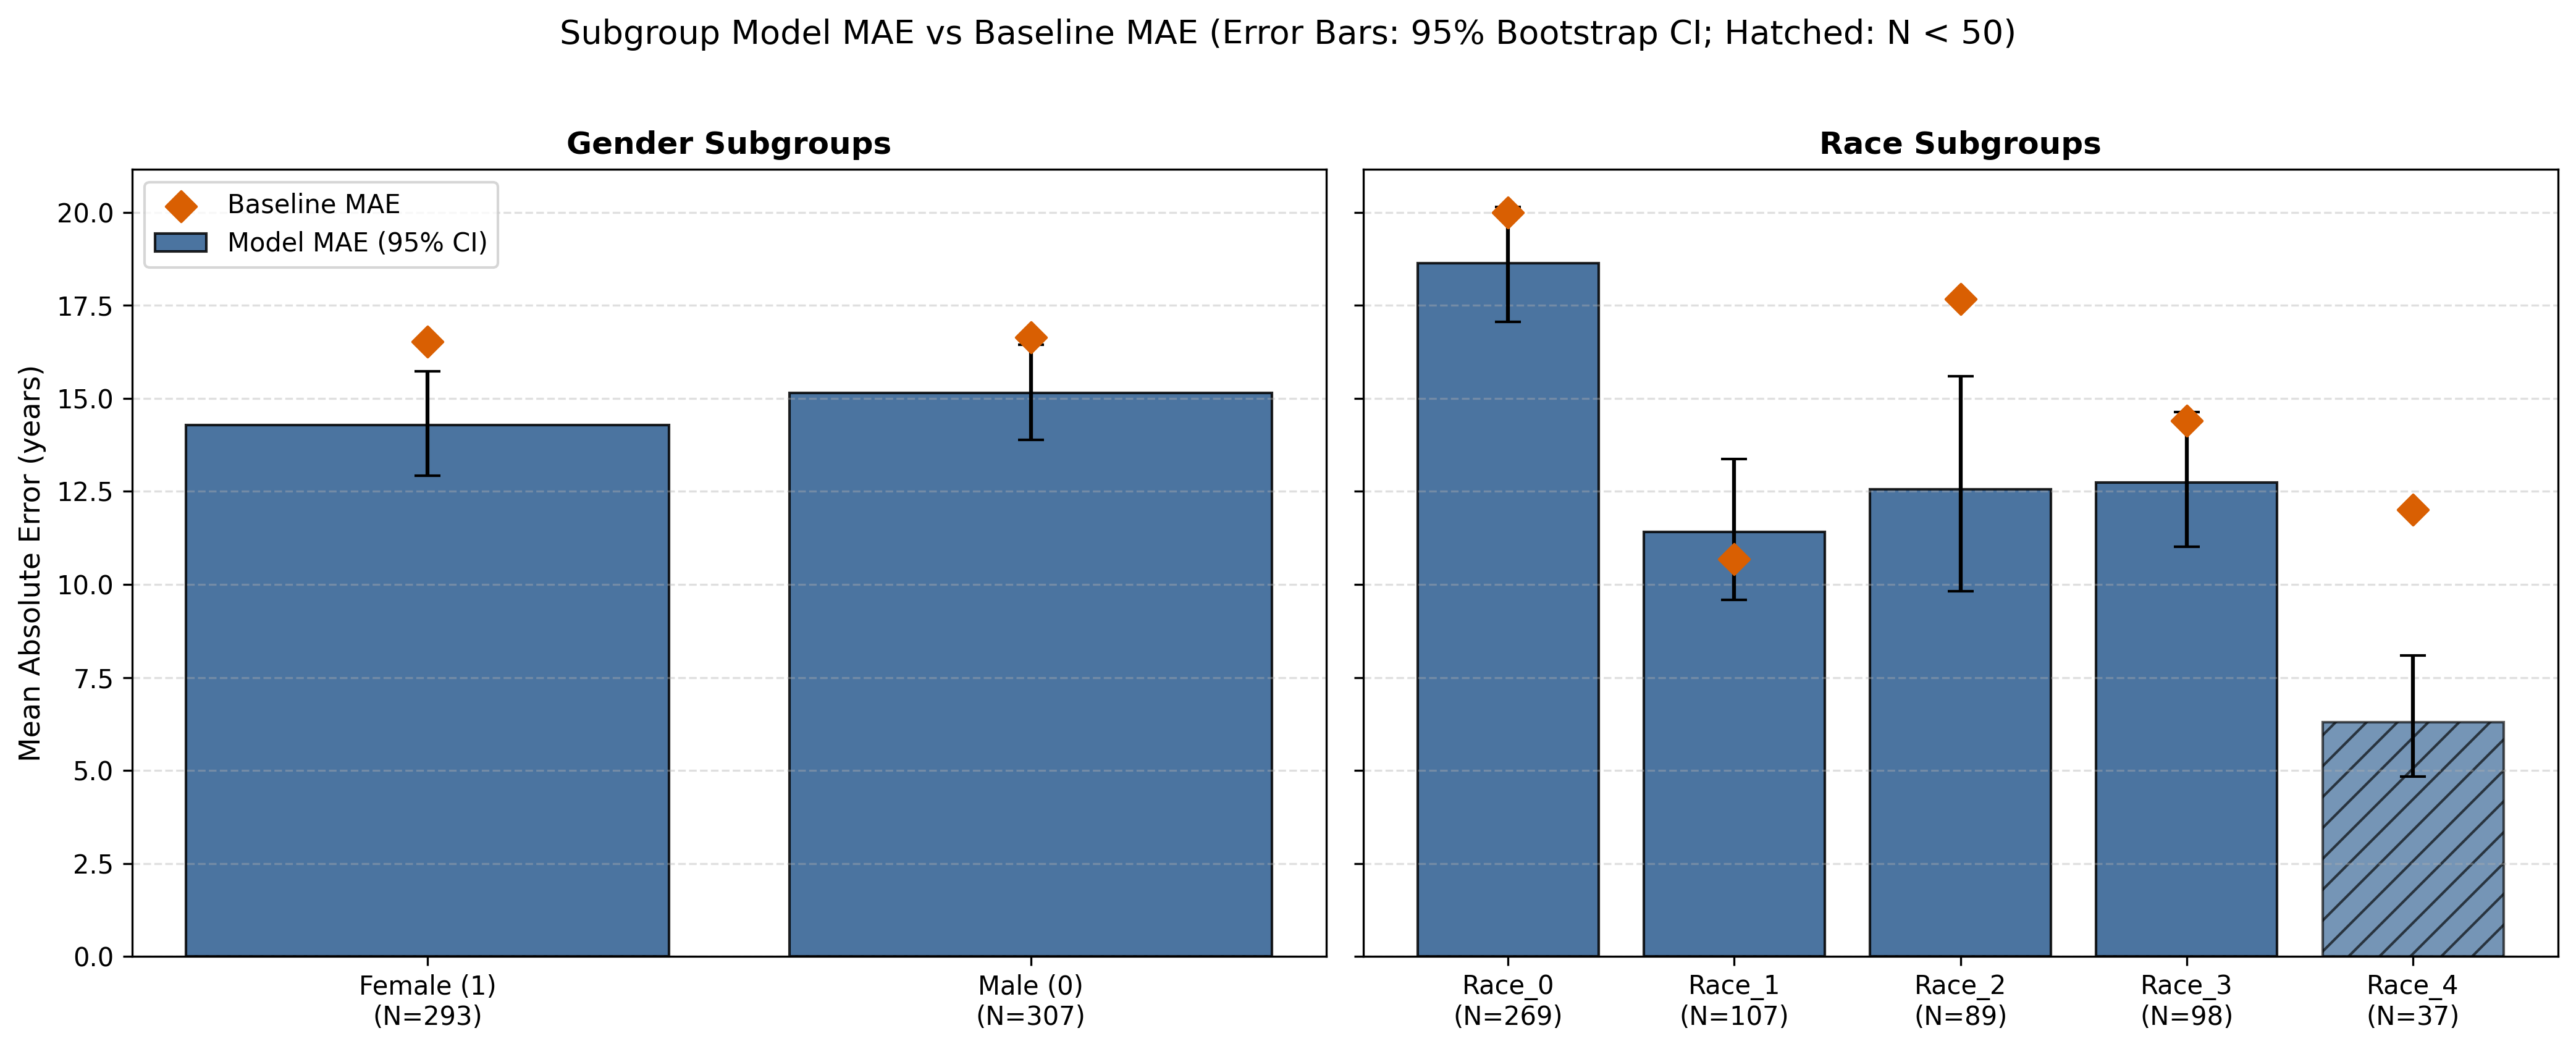

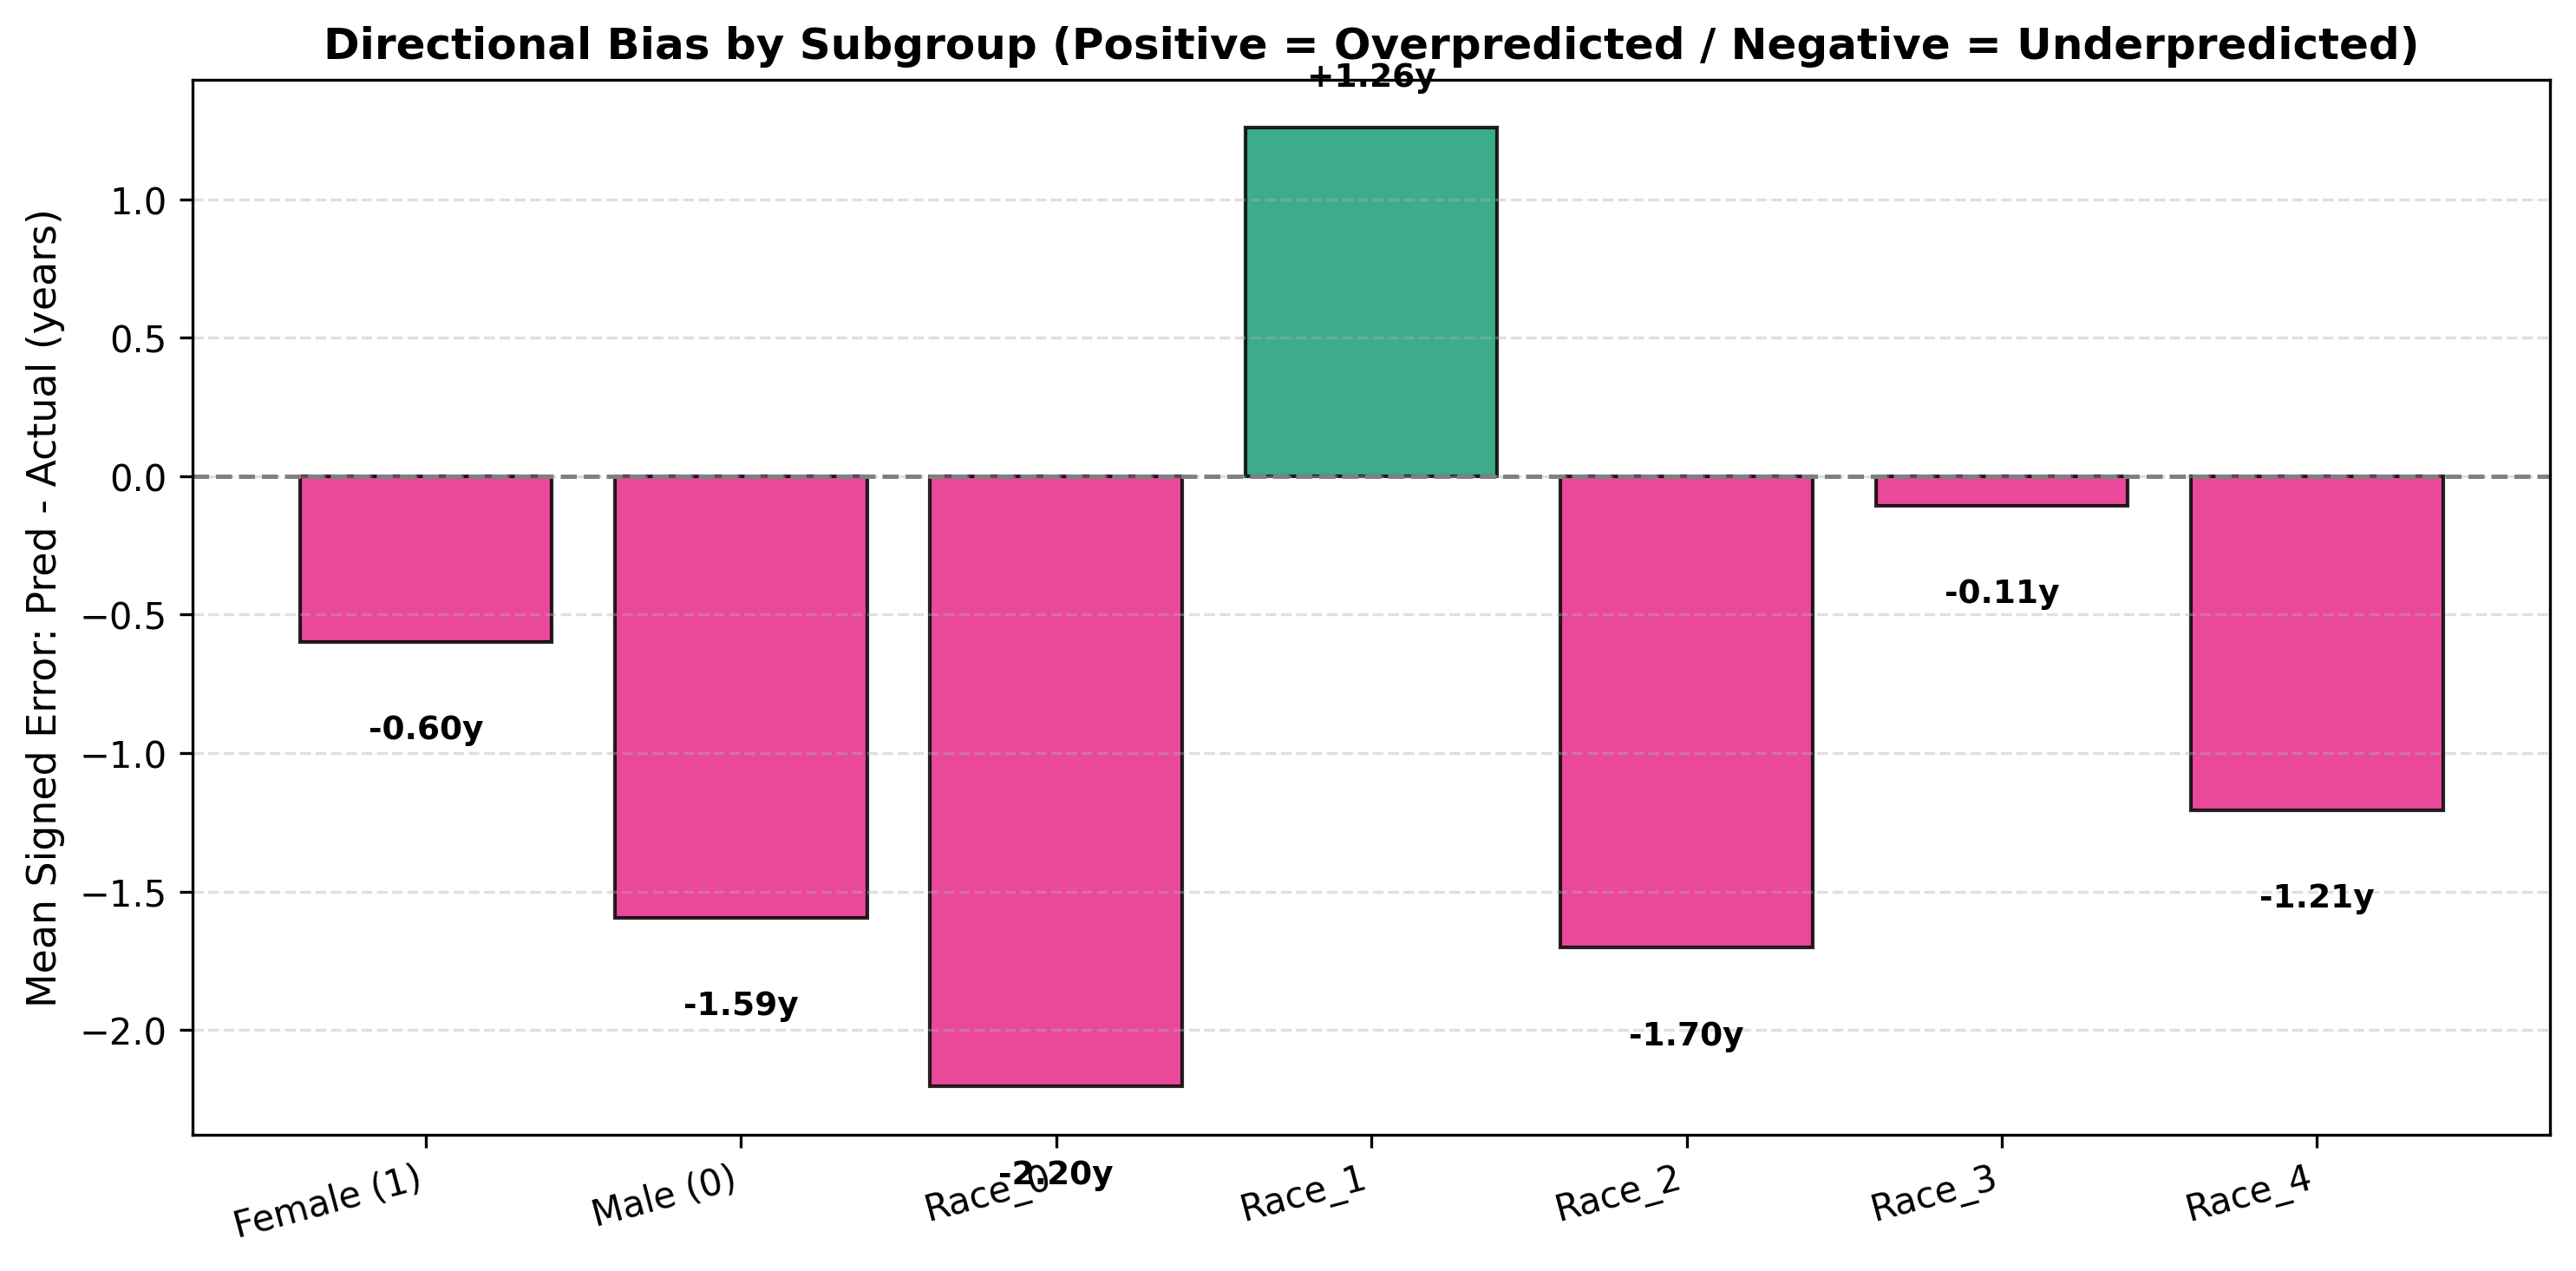

In [5]:
# Cell 6: Visualizations of Subgroup Error and Directional Bias
# Figure 1: Two-Panel Bar Chart of Model_MAE with Bootstrap Error Bars and Baseline Markers
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

for ax, df_curr, title in zip(axes, [df_gender_sub, df_race_sub], ["Gender Subgroups", "Race Subgroups"]):
    x_pos = np.arange(len(df_curr))
    y_err = [
        df_curr["Model_MAE"] - df_curr["MAE_CI_low"],
        df_curr["MAE_CI_high"] - df_curr["Model_MAE"]
    ]
    
    # Bar plot for Model_MAE
    bars = ax.bar(x_pos, df_curr["Model_MAE"], yerr=y_err, capsize=5,
                  color="#2b5c8f", alpha=0.85, edgecolor="black", label="Model MAE (95% CI)")
    
    # Apply hatch pattern to small groups (N < 50)
    for i, is_small in enumerate(df_curr["Small_group"]):
        if is_small:
            bars[i].set_hatch("//")
            bars[i].set_alpha(0.65)
    
    # Overlay Baseline MAE markers
    ax.scatter(x_pos, df_curr["Baseline_MAE"], color="#d95f02", marker="D", s=70, zorder=5, label="Baseline MAE")
    
    # Group size annotations under each label
    labels_with_n = [f"{grp}\n(N={n})" for grp, n in zip(df_curr["Group"], df_curr["N"])]
    ax.set_xticks(x_pos)
    ax.set_xticklabels(labels_with_n, fontsize=10)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.grid(True, axis="y", linestyle="--", alpha=0.4)
    if ax == axes[0]:
        ax.set_ylabel("Mean Absolute Error (years)", fontsize=11)
        ax.legend(loc="upper left")

plt.suptitle("Subgroup Model MAE vs Baseline MAE (Error Bars: 95% Bootstrap CI; Hatched: N < 50)", fontsize=13, y=1.02)
plt.tight_layout()
fig28_path = "visualizations/28_subgroup_mae.png"
plt.savefig(fig28_path, dpi=300, bbox_inches="tight")
plt.show()

# Figure 2: Mean Signed Error per Subgroup (Directional Bias)
fig, ax = plt.subplots(figsize=(10, 5))
all_groups = list(df_gender_sub["Group"]) + list(df_race_sub["Group"])
all_signed_err = list(df_gender_sub["Mean_signed_error"]) + list(df_race_sub["Mean_signed_error"])
colors = ["#1b9e77" if val >= 0 else "#e7298a" for val in all_signed_err]

bars = ax.bar(all_groups, all_signed_err, color=colors, edgecolor="black", alpha=0.85)
ax.axhline(0, color="gray", linestyle="--", linewidth=1.2)
ax.set_ylabel("Mean Signed Error: Pred - Actual (years)", fontsize=11)
ax.set_title("Directional Bias by Subgroup (Positive = Overpredicted / Negative = Underpredicted)", fontsize=12, fontweight="bold")
ax.grid(True, axis="y", linestyle="--", alpha=0.4)

# Value labels on bars
for bar, val in zip(bars, all_signed_err):
    y_pos = val + 0.15 if val >= 0 else val - 0.35
    ax.text(bar.get_x() + bar.get_width() / 2, y_pos, f"{val:+.2f}y", ha="center", fontsize=9, fontweight="bold")

plt.xticks(rotation=15, ha="right", fontsize=10)
plt.tight_layout()
fig29_path = "visualizations/29_subgroup_signed_error.png"
plt.savefig(fig29_path, dpi=300, bbox_inches="tight")
plt.show()


=== Overall Performance: Full Model vs. Geometry-Only Model ===
Full Model (Geometry + Demographics): Test MAE = 14.7200, Test R² = 0.1719
Geometry-Only Model (Continuous Only): Test MAE = 15.5303, Test R² = 0.1152
Impact of Dropping Demographics:        ΔMAE = +0.8103 years, ΔR² = -0.0566

=== Subgroup Comparison: Full vs. Geometry-Only Model ===
Attribute      Group  Full_MAE  Geom_MAE  Diff_MAE  Full_Signed_Error  Geom_Signed_Error  Diff_Signed_Error
   Gender Female (1)    14.277    15.482     1.205             -0.599              1.220              1.818
   Gender   Male (0)    15.143    15.576     0.434             -1.594             -3.644             -2.050
     Race     Race_0    18.628    18.736     0.107             -2.204             -6.471             -4.267
     Race     Race_1    11.416    11.988     0.572              1.258              2.280              1.022
     Race     Race_2    12.556    14.527     1.970             -1.703              3.745              5.447
  

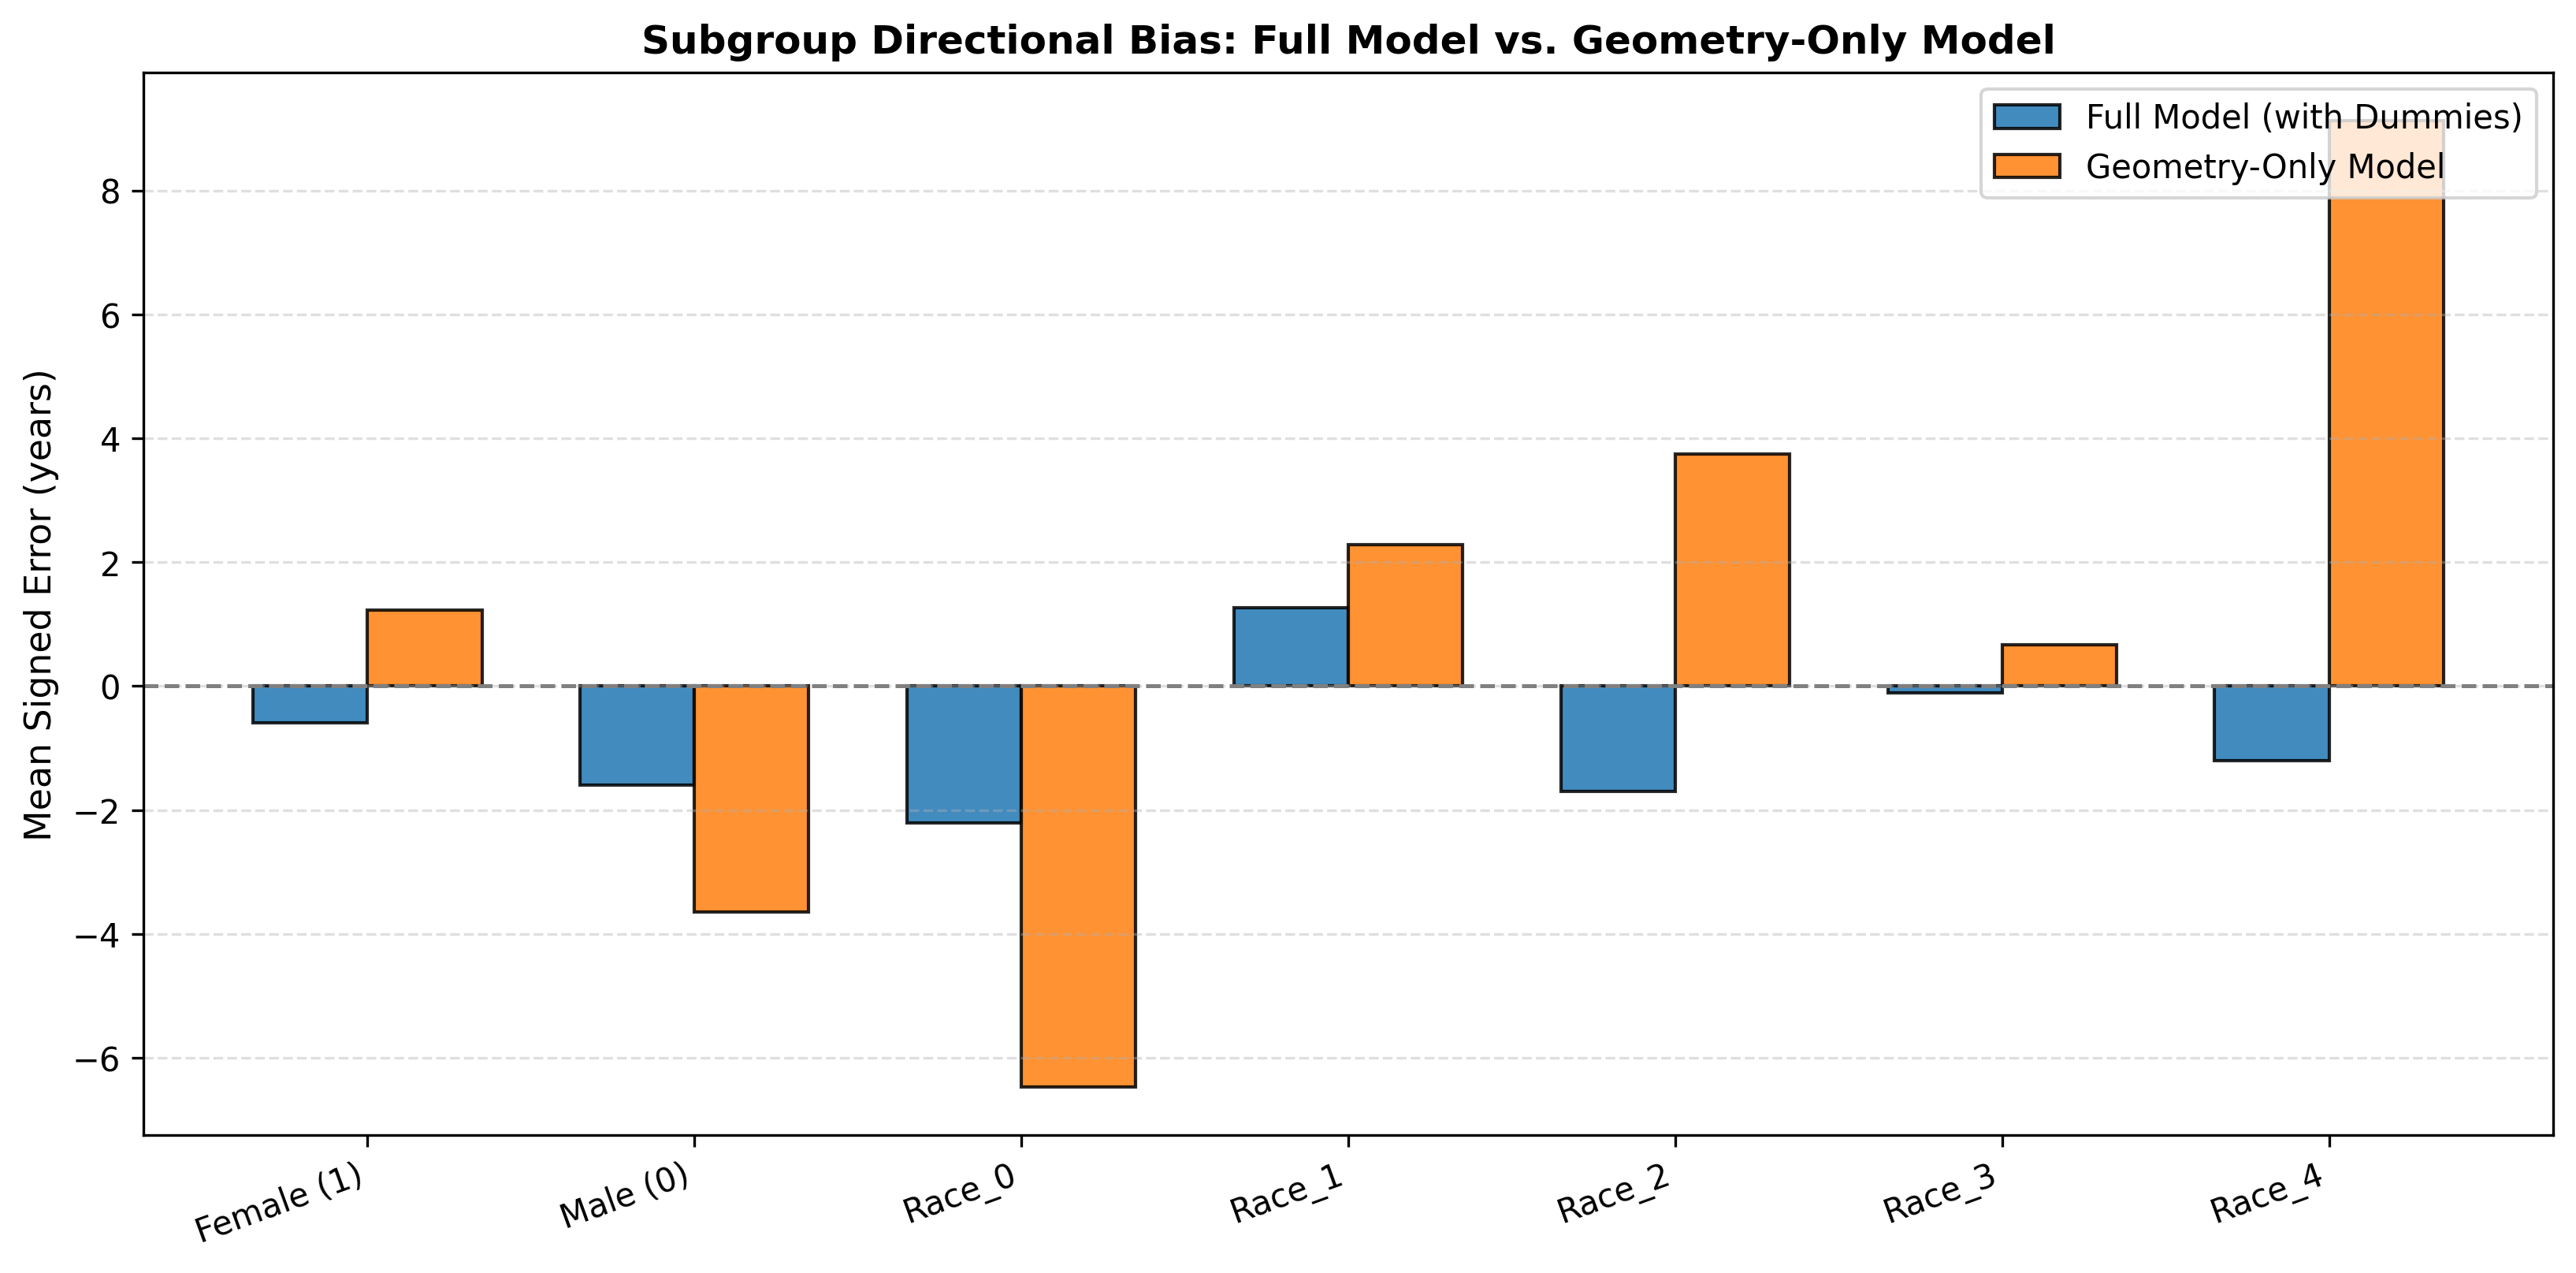

In [6]:
# Cell 7: Assessing the Impact of Removing Demographic Predictors (Geometry-Only Model)
# Fit geometry-only model (scaling continuous features only, excluding demographic dummies)
pipe_geom = Pipeline([
    ("prep", ColumnTransformer([("s", StandardScaler(), continuous_cols)])),
    ("reg", LinearRegression())
])

pipe_geom.fit(X_train[continuous_cols], y_train)
y_pred_geom = pipe_geom.predict(X_test[continuous_cols])

# Overall performance comparison
mae_full = mean_absolute_error(y_test, y_pred_chosen)
r2_full = r2_score(y_test, y_pred_chosen)
mae_geom = mean_absolute_error(y_test, y_pred_geom)
r2_geom = r2_score(y_test, y_pred_geom)

print("=== Overall Performance: Full Model vs. Geometry-Only Model ===")
print(f"Full Model (Geometry + Demographics): Test MAE = {mae_full:.4f}, Test R² = {r2_full:.4f}")
print(f"Geometry-Only Model (Continuous Only): Test MAE = {mae_geom:.4f}, Test R² = {r2_geom:.4f}")
print(f"Impact of Dropping Demographics:        ΔMAE = {mae_geom - mae_full:+.4f} years, ΔR² = {r2_geom - r2_full:+.4f}")

# Subgroup comparison table
comp_records = []
for attr, labels in [("Gender", gender_label), ("Race", race_label)]:
    for grp in sorted(pd.Series(labels).unique()):
        mask = (labels == grp)
        y_true_g = y_test[mask]
        f_mae = mean_absolute_error(y_true_g, y_pred_chosen[mask])
        g_mae = mean_absolute_error(y_true_g, y_pred_geom[mask])
        f_se = np.mean(y_pred_chosen[mask] - y_true_g.values)
        g_se = np.mean(y_pred_geom[mask] - y_true_g.values)
        comp_records.append({
            "Attribute": attr,
            "Group": grp,
            "Full_MAE": f_mae,
            "Geom_MAE": g_mae,
            "Diff_MAE": g_mae - f_mae,
            "Full_Signed_Error": f_se,
            "Geom_Signed_Error": g_se,
            "Diff_Signed_Error": g_se - f_se
        })

df_comp = pd.DataFrame(comp_records)
print("\n=== Subgroup Comparison: Full vs. Geometry-Only Model ===")
print(df_comp.round(3).to_string(index=False))

# Grouped bar chart of signed error (Full vs Geometry-only)
fig, ax = plt.subplots(figsize=(11, 5.5))
x_pos = np.arange(len(df_comp))
width = 0.35

ax.bar(x_pos - width/2, df_comp["Full_Signed_Error"], width, label="Full Model (with Dummies)", color="#1f77b4", alpha=0.85, edgecolor="black")
ax.bar(x_pos + width/2, df_comp["Geom_Signed_Error"], width, label="Geometry-Only Model", color="#ff7f0e", alpha=0.85, edgecolor="black")

ax.axhline(0, color="gray", linestyle="--", linewidth=1.2)
ax.set_xticks(x_pos)
ax.set_xticklabels(df_comp["Group"], rotation=20, ha="right", fontsize=10)
ax.set_ylabel("Mean Signed Error (years)", fontsize=11)
ax.set_title("Subgroup Directional Bias: Full Model vs. Geometry-Only Model", fontsize=12, fontweight="bold")
ax.legend(loc="upper right", fontsize=10)
ax.grid(True, axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
fig30_path = "visualizations/30_subgroup_full_vs_geometry_only.png"
plt.savefig(fig30_path, dpi=300, bbox_inches="tight")
plt.show()

# Note: Dropping protected demographic attributes (gender, race) does not guarantee
# fairness because facial geometry measurements (e.g., face width, height, aspect ratio)
# correlate with sex and ancestry, acting as statistical proxies. Notice that omitting demographic
# variables increases directional error (e.g. Race_0 underpredicted by -6.47y, Race_4 overpredicted by +9.12y).


In [7]:
# Cell 8: Consolidated CE2 Experimental Results and Master Summary Export
def load_if_exists(path):
    if os.path.exists(path):
        return pd.read_csv(path)
    else:
        print(f"Warning: File '{path}' not found. Skipping.")
        return None

# Load available result tables
df_model_res = load_if_exists("data/processed/ce2_model_results.csv")
df_ablation_res = load_if_exists("data/processed/ce2_ablation_results.csv")
df_bv_res = load_if_exists("data/processed/ce2_bias_variance_results.csv")
df_clf_res = load_if_exists("data/processed/ce2_classification_results.csv")
df_clust_res = load_if_exists("data/processed/ce2_clustering_results.csv")

# Print available tables with headers
print("=" * 80)
print("                    CE2 CONSOLIDATED EXPERIMENTAL RESULTS")
print("=" * 80)

if df_model_res is not None:
    print("\n--- 1. Regression Models (CE2 Phase 3 - 5) ---")
    print(df_model_res.round(4).to_string(index=False))

if df_ablation_res is not None:
    print("\n--- 2. Feature Ablation Study (CE2 Phase 4) ---")
    print(df_ablation_res.round(4).to_string(index=False))

if df_bv_res is not None:
    print("\n--- 3. Bias-Variance & Complexity Analysis (CE2 Phase 8) ---")
    print(df_bv_res.round(4).to_string(index=False))

if df_clf_res is not None:
    print("\n--- 4. Classification Models (CE2 Phase 9, Sorted by F1_macro Descending) ---")
    df_clf_sorted = df_clf_res.sort_values(by="F1_macro", ascending=False)
    print(df_clf_sorted.round(4).to_string(index=False))

if df_clust_res is not None:
    print("\n--- 5. Unsupervised Clustering & PCA (CE2 Phase 10) ---")
    print(df_clust_res.round(4).to_string(index=False))

print("\n--- 6. Subgroup Fairness & Disparities (CE2 Phase 11) ---")
print(df_subgroup_all.round(4).to_string(index=False))

# Write master consolidated summary to text file
summary_file_path = "data/processed/ce2_final_summary.txt"
with open(summary_file_path, "w") as f:
    f.write("=" * 80 + "\n")
    f.write("             CE2: FACIAL FEATURE ANALYSIS AND AGE PREDICTION\n")
    f.write("                     CONSOLIDATED RESULTS SUMMARY\n")
    f.write("=" * 80 + "\n\n")
    
    if df_model_res is not None:
        f.write("1. REGRESSION MODEL BENCHMARKS\n" + "-" * 35 + "\n")
        f.write(df_model_res.round(4).to_string(index=False) + "\n\n")
        
    if df_ablation_res is not None:
        f.write("2. FEATURE ABLATION STUDY\n" + "-" * 30 + "\n")
        f.write(df_ablation_res.round(4).to_string(index=False) + "\n\n")
        
    if df_bv_res is not None:
        f.write("3. BIAS-VARIANCE DECOMPOSITION\n" + "-" * 35 + "\n")
        f.write(df_bv_res.round(4).to_string(index=False) + "\n\n")
        
    if df_clf_res is not None:
        f.write("4. CLASSIFICATION OF LIFE-STAGE AGE GROUPS (Sorted by F1 Macro)\n" + "-" * 65 + "\n")
        f.write(df_clf_sorted.round(4).to_string(index=False) + "\n\n")
        
    if df_clust_res is not None:
        f.write("5. UNSUPERVISED CLUSTERING & GEOMETRIC PCA\n" + "-" * 45 + "\n")
        f.write(df_clust_res.round(4).to_string(index=False) + "\n\n")
        
    f.write("6. SUBGROUP FAIRNESS & ERROR PARITY (TEST SET)\n" + "-" * 50 + "\n")
    f.write(df_subgroup_all.round(4).to_string(index=False) + "\n\n")
    f.write("=" * 80 + "\n")

print(f"\nMaster consolidated summary successfully exported to '{summary_file_path}'.")


                    CE2 CONSOLIDATED EXPERIMENTAL RESULTS

--- 1. Regression Models (CE2 Phase 3 - 5) ---
                           Model  Train_MAE  Test_MAE  Train_RMSE  Test_RMSE  Train_R2  Test_R2  Train_MSE  Test_MSE
                 Baseline (Mean)    15.5015   16.5798     20.0591    21.0996    0.0000  -0.0021   402.3679  445.1925
   Simple LR (face_aspect_ratio)    15.2493   16.1086     19.3774    20.3385    0.0668   0.0689   375.4821  413.6566
      Multiple Linear Regression    13.8583   14.7200     18.1997    19.1813    0.1768   0.1719   331.2289  367.9220
Polynomial Regression (degree 2)    13.6784   14.6535     17.9914    19.1044    0.1955   0.1785   323.6897  364.9775

--- 2. Feature Ablation Study (CE2 Phase 4) ---
                   Feature_Set  Train_R2  Test_R2  Test_MAE  Test_RMSE
             Demographics Only    0.0764   0.0744   15.6530    20.2784
                 Geometry Only    0.1212   0.1152   15.5303    19.8263
Both (Demographics + Geometry)    0.1768   0.17

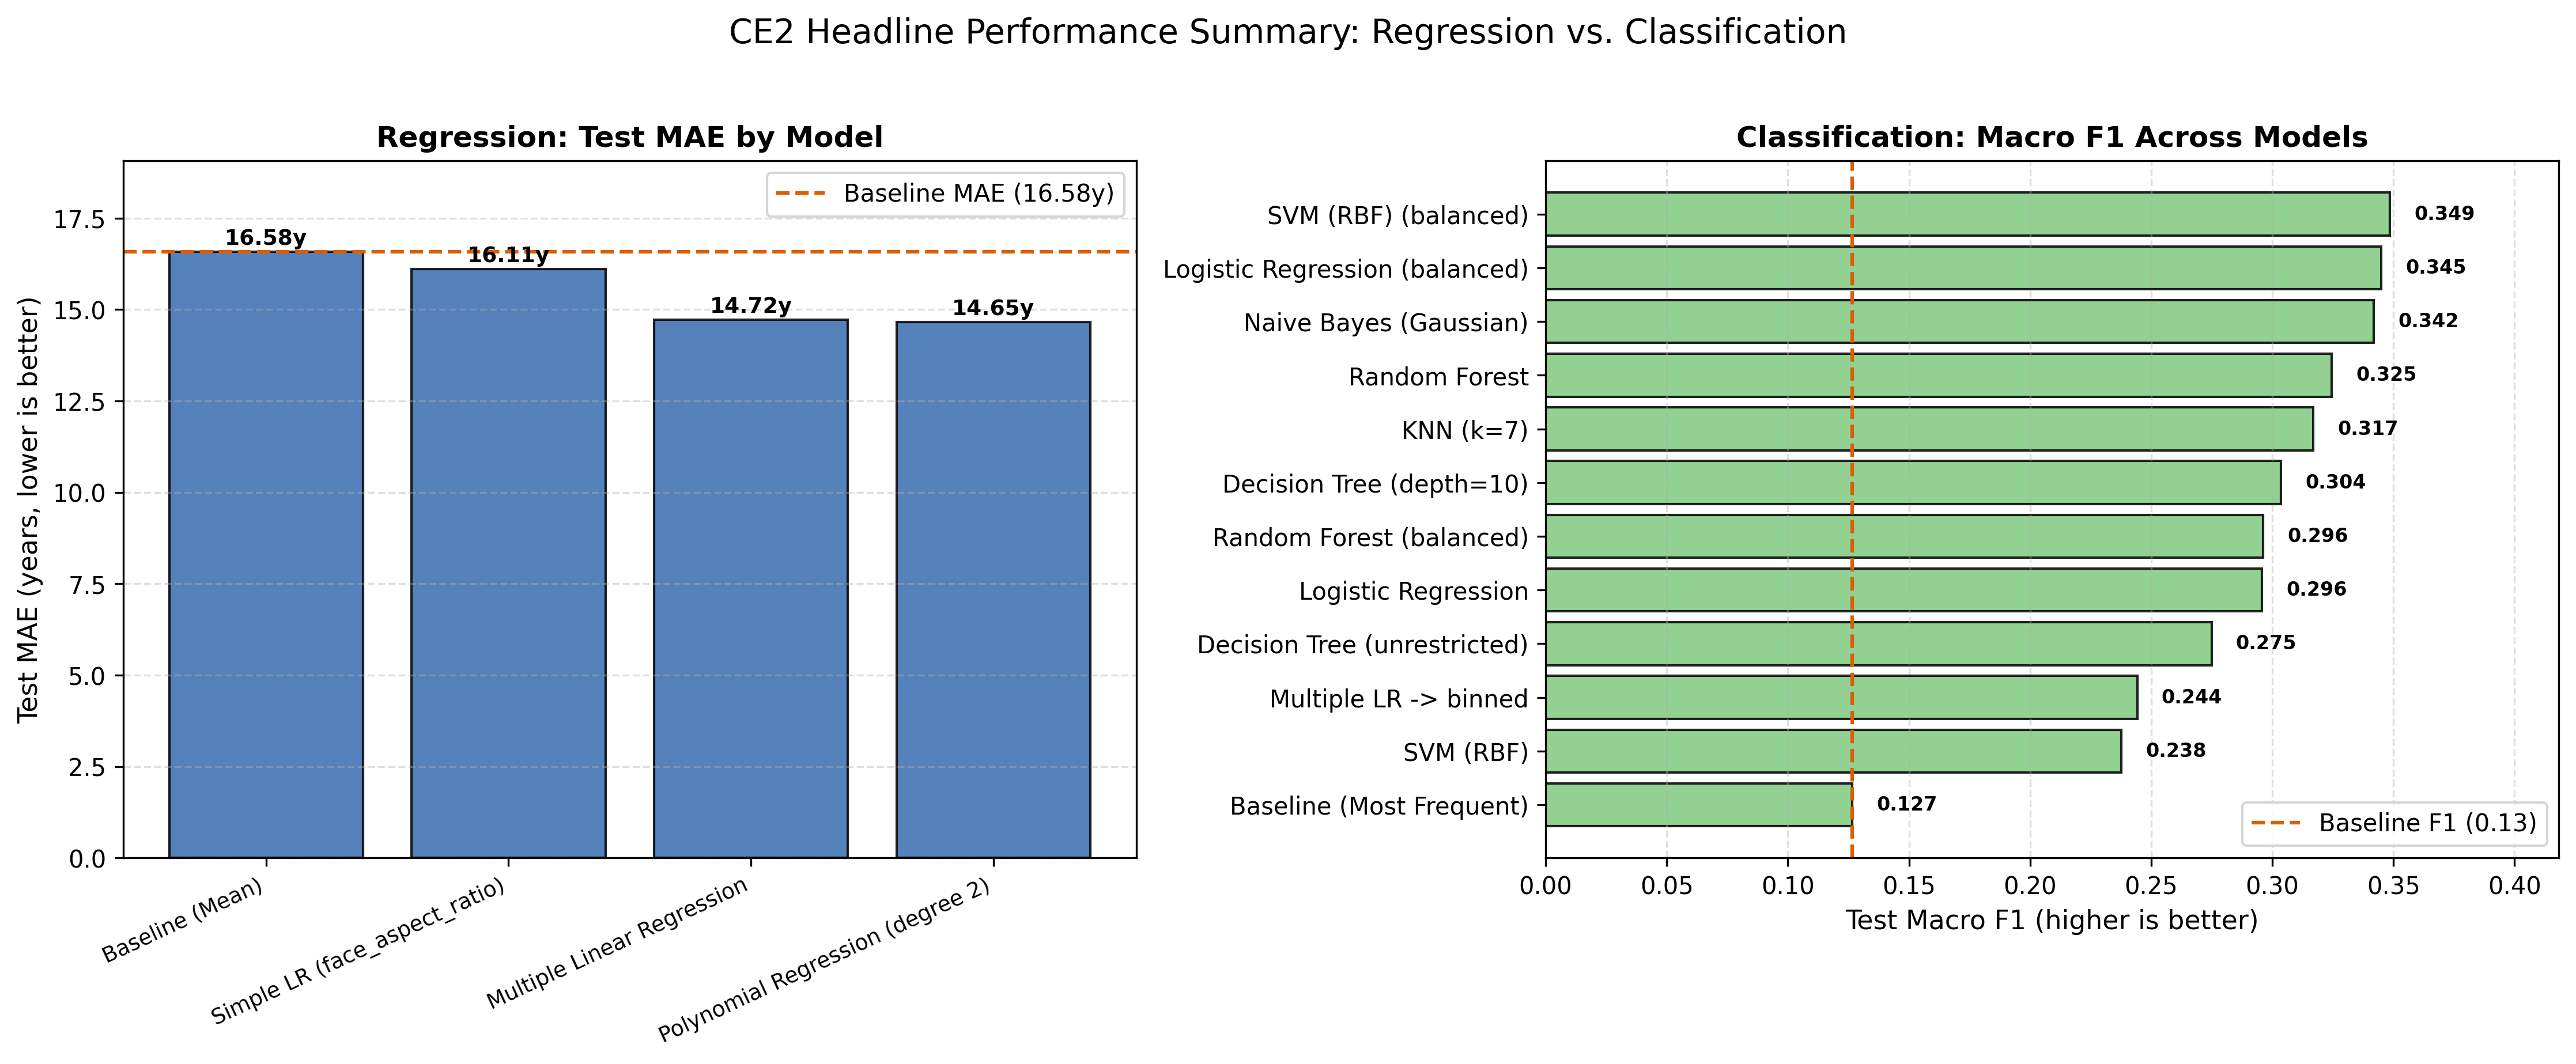

In [8]:
# Cell 9: CE2 Headline Visualization (Regression Test MAE & Classification F1 Macro)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Panel 1: Regression Test MAE
if df_model_res is not None and "Test_MAE" in df_model_res.columns:
    models_reg = df_model_res["Model"].tolist()
    mae_reg = df_model_res["Test_MAE"].tolist()
    
    # Identify baseline value
    base_val = mae_reg[0] if "Baseline" in models_reg[0] else 16.58
    
    bars1 = ax1.bar(models_reg, mae_reg, color="#386cb0", alpha=0.85, edgecolor="black")
    ax1.axhline(base_val, color="#d95f02", linestyle="--", linewidth=1.5, label=f"Baseline MAE ({base_val:.2f}y)")
    
    # Annotate bar values
    for bar in bars1:
        h = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2, h + 0.2, f"{h:.2f}y", ha="center", fontsize=9, fontweight="bold")
        
    ax1.set_ylabel("Test MAE (years, lower is better)", fontsize=11)
    ax1.set_title("Regression: Test MAE by Model", fontsize=12, fontweight="bold")
    ax1.set_xticklabels(models_reg, rotation=25, ha="right", fontsize=9)
    ax1.set_ylim(0, max(mae_reg) * 1.15)
    ax1.grid(True, axis="y", linestyle="--", alpha=0.4)
    ax1.legend(loc="upper right", fontsize=10)
else:
    ax1.text(0.5, 0.5, "Regression results file missing", ha="center", va="center")
    print("Warning: ce2_model_results.csv not found for headline figure.")

# Panel 2: Classification Macro F1
if df_clf_res is not None and "F1_macro" in df_clf_res.columns:
    df_clf_plot = df_clf_res.sort_values(by="F1_macro", ascending=True)
    models_clf = df_clf_plot["Model"].tolist()
    f1_clf = df_clf_plot["F1_macro"].tolist()
    
    # Locate baseline
    base_clf_row = df_clf_res[df_clf_res["Model"].str.contains("Baseline", case=False, na=False)]
    base_f1 = base_clf_row["F1_macro"].iloc[0] if len(base_clf_row) > 0 else 0.12
    
    bars2 = ax2.barh(models_clf, f1_clf, color="#7fc97f", alpha=0.85, edgecolor="black")
    ax2.axvline(base_f1, color="#d95f02", linestyle="--", linewidth=1.5, label=f"Baseline F1 ({base_f1:.2f})")
    
    # Annotate bar values
    for bar in bars2:
        w = bar.get_width()
        ax2.text(w + 0.01, bar.get_y() + bar.get_height()/2, f"{w:.3f}", va="center", fontsize=8, fontweight="bold")
        
    ax2.set_xlabel("Test Macro F1 (higher is better)", fontsize=11)
    ax2.set_title("Classification: Macro F1 Across Models", fontsize=12, fontweight="bold")
    ax2.set_xlim(0, max(f1_clf) * 1.2)
    ax2.grid(True, axis="x", linestyle="--", alpha=0.4)
    ax2.legend(loc="lower right", fontsize=10)
else:
    ax2.text(0.5, 0.5, "Classification results file missing", ha="center", va="center")
    print("Warning: ce2_classification_results.csv not found for headline figure.")

plt.suptitle("CE2 Headline Performance Summary: Regression vs. Classification", fontsize=14, y=1.02)
plt.tight_layout()
fig31_path = "visualizations/31_ce2_headline_results.png"
plt.savefig(fig31_path, dpi=300, bbox_inches="tight")
plt.show()


## Ethical Considerations of Facial Analysis

Deploying machine learning models for facial analysis introduces significant ethical, legal, and human rights considerations. The following points outline fundamental ethical dimensions relevant to this investigation:

- **Biometric privacy**: facial images and landmark measurements are biometric data; consent of the pictured individuals for this specific analysis cannot be verified from the dataset documentation used here; this project stores only derived measurements in its processed files and keeps raw images out of the repository (.gitignore).
- **Representation**: the race distribution in our sample is imbalanced (Race_0 about 44.8% versus Race_4 about 6.2%), race categories are coarse (one category groups "Others"), and gender is recorded as binary; estimates for small groups are noisy.
- **Using gender and race as model inputs** is ethically and legally sensitive; the ablation above tests how much they matter.
- **Real-world risk**: an age estimate with an average error of ~14.7 years (with subgroup errors ranging from 6.3 to 18.6 years) is unsuitable for any real decision (age verification, profiling, surveillance), and unequal errors across groups could cause unequal treatment.
- **Fairness definitions**: this notebook measures error parity across groups; demographic parity applies to decision outcomes and would need a decision rule.
- **Mitigation and limits**: report subgroup performance, document limitations, do not deploy, collect balanced consented data.
- Findings from this project's subgroup analysis: [to be filled in]


## CE2 Syllabus Coverage

| Topic | Notebook | Status |
| :--- | :--- | :--- |
| Train-test split, feature scaling | 12 | Implemented |
| Simple, Multiple, Polynomial Regression | 13, 14 | Implemented |
| MAE, MSE, RMSE, R2 | 13, 15 | Implemented |
| Cross-validation | 15 | Implemented |
| Overfitting, underfitting, bias-variance | 16 | Implemented |
| Logistic Regression, KNN, Decision Tree, Random Forest, Naive Bayes, SVM | 17 | Implemented |
| Confusion matrix, accuracy, precision, recall, F1 | 17 | Implemented |
| K-Means, Hierarchical, DBSCAN, silhouette score | 18 | Implemented |
| PCA | 18 | Implemented |
| Ethical considerations | 19 | Implemented |
| Association rules, recommender systems | — | Conceptual only (no transaction-style data) |
| Reinforcement learning | — | Conceptual only (no environment or reward) |


## Observation

[To be filled in]


## CE2 Conclusion

[To be filled in]


## Future Scope

[To be filled in]
